<a href="https://colab.research.google.com/github/bahaali273/linear-regression-lab/blob/main/Linear_Regression_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes

# Load the dataset
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame

# Inspect the dataset
print("First five rows:")
display(df.head())

print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nSummary statistics:")
display(df.describe())


First five rows:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


Dataset shape: (442, 11)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB

Missing values:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Summary statistics:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


### Task 1.1 — Dataset Inspection

The Diabetes dataset contains 442 observations and 11 columns, including 10 independent variables and one dependent variable.

- **Dependent variable:** `target`, representing a quantitative measure of diabetes disease progression one year after baseline.
- **Independent variables:** `age`, `sex`, `bmi`, `bp`, `s1`, `s2`, `s3`, `s4`, `s5`, and `s6`.
- **Missing values:** No missing values were found in any column.
- **Summary statistics:** The target has a mean of 152.13, a standard deviation of 77.09, and values ranging from 25 to 346.

The features have been scaled, while the target remains in its original numerical scale.

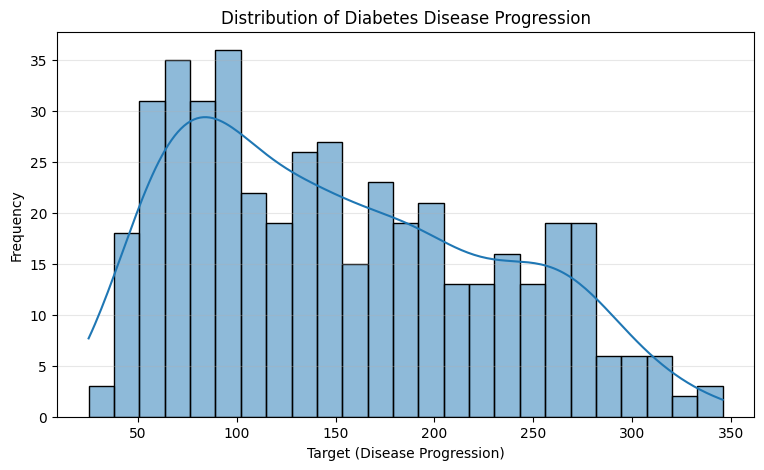

In [ ]:

# Task 1.1 — Target distribution

plt.figure(figsize=(9, 5))

sns.histplot(
    df["target"],
    bins=25,
    kde=True
)

plt.title("Distribution of Diabetes Disease Progression")
plt.xlabel("Target (Disease Progression)")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)

plt.show()


**Target Distribution Interpretation**

The histogram shows that disease progression values range from approximately 25 to 346. Most observations are concentrated between 50 and 200, with fewer observations at higher values. The distribution is somewhat right-skewed and does not appear perfectly normal.

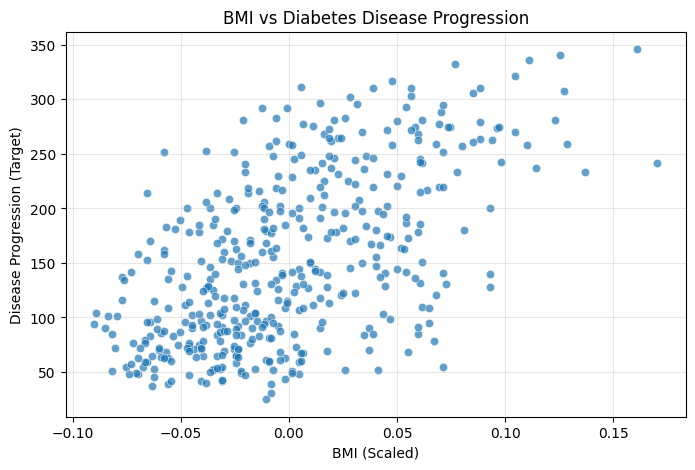

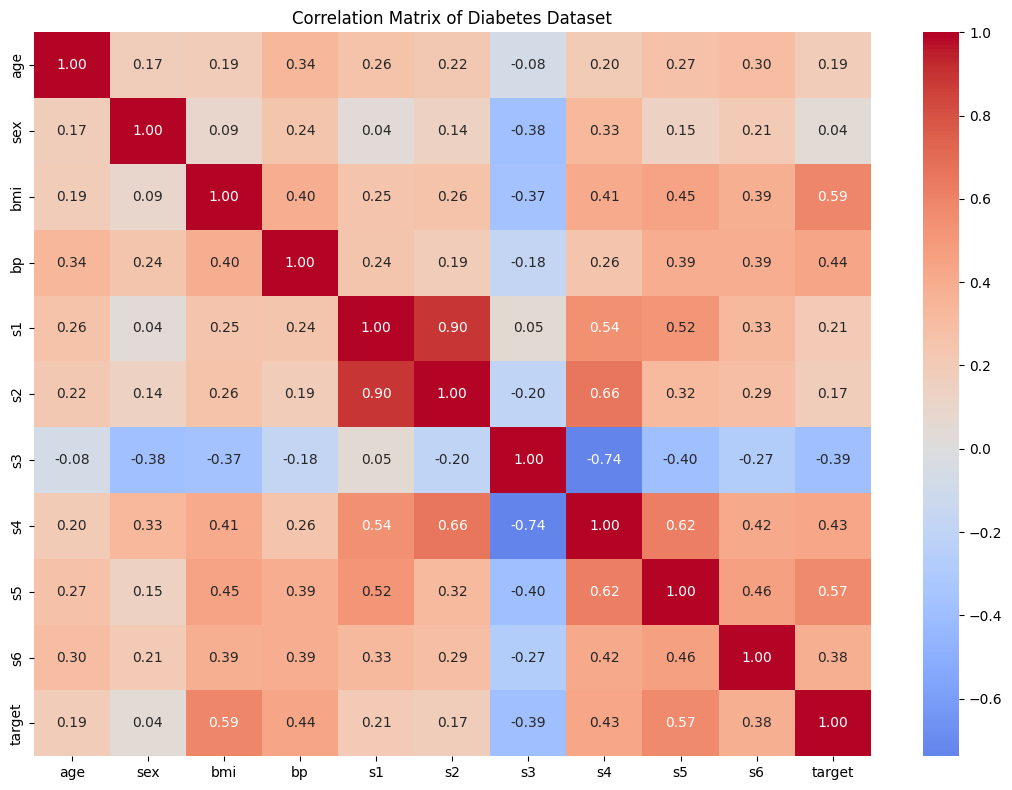

Features ranked by absolute correlation with target:
bmi    0.586450
s5     0.565883
bp     0.441482
s4     0.430453
s3    -0.394789
s6     0.382483
s1     0.212022
age    0.187889
s2     0.174054
sex    0.043062
Name: target, dtype: float64


In [ ]:

# Task 1.2 — BMI Relationship and Correlation Heatmap

# 1. BMI versus target scatter plot
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="bmi", y="target", alpha=0.7)

plt.title("BMI vs Diabetes Disease Progression")
plt.xlabel("BMI (Scaled)")
plt.ylabel("Disease Progression (Target)")
plt.grid(alpha=0.3)
plt.show()

# 2. Correlation matrix heatmap
plt.figure(figsize=(11, 8))

correlation_matrix = df.corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Diabetes Dataset")
plt.tight_layout()
plt.show()

# 3. Features with strongest target correlations
target_correlations = (
    correlation_matrix["target"]
    .drop("target")
    .sort_values(key=abs, ascending=False)
)

print("Features ranked by absolute correlation with target:")
print(target_correlations)


### Task 1.2 — Feature Relationships

**1. Relationship between BMI and the target**

BMI has a moderate positive correlation with the target (r = 0.5865). The scatter plot shows an upward trend, suggesting that higher BMI values are generally associated with higher disease progression values. However, the observations are spread out, indicating that BMI alone cannot fully explain the variation in the target.

**2. Three strongest absolute correlations with the target**

The three strongest features are:

- BMI: 0.5865
- S5: 0.5659
- BP: 0.4415

All three features have positive correlations with disease progression.

**3. Does correlation imply causation?**

No. Correlation indicates an association between variables but does not establish a cause-and-effect relationship. Other factors or confounding variables may influence the observed relationship.

In [ ]:

# Part 2 — Simple Linear Regression

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Select BMI as the independent variable
X = df[["bmi"]]

# Select disease progression as the target
y = df["target"]

# Split dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Create and train the linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Display training and testing sizes
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

# Display the fitted model parameters
print("Intercept:", model.intercept_)
print("BMI Coefficient:", model.coef_[0])

# Generate predictions
y_pred = model.predict(X_test)

print("\nFirst five predictions:")
print(y_pred[:5])




# Linear Regression Equation:
# y_pred = b0 + b1 * x
#
# y_pred: The predicted value of the target (disease progression).
# b0: The intercept, where the regression line crosses the Y-axis.
# b1: The coefficient (slope), which represents how much the
#     predicted target changes when X increases by one unit.
# x: The independent variable (BMI in this model).
#
# The model learns b0 and b1 from the training data
# by minimizing the sum of squared prediction errors.


Training observations: 353
Testing observations: 89
Intercept: 152.00335421448167
BMI Coefficient: 998.5776891375598

First five predictions:
[145.80622687 188.85739048 147.95878505 203.92529774 131.8145987 ]



# Fitted Model:
# Predicted target = 152.0034 + 998.5777 * BMI
#
# The positive BMI coefficient indicates that higher BMI
# values are associated with higher predicted disease
# progression values.
#
# The intercept (152.0034) is the predicted target
# when the scaled BMI value equals zero.
#
# Training observations: 353 (80%)
# Testing observations: 89 (20%)


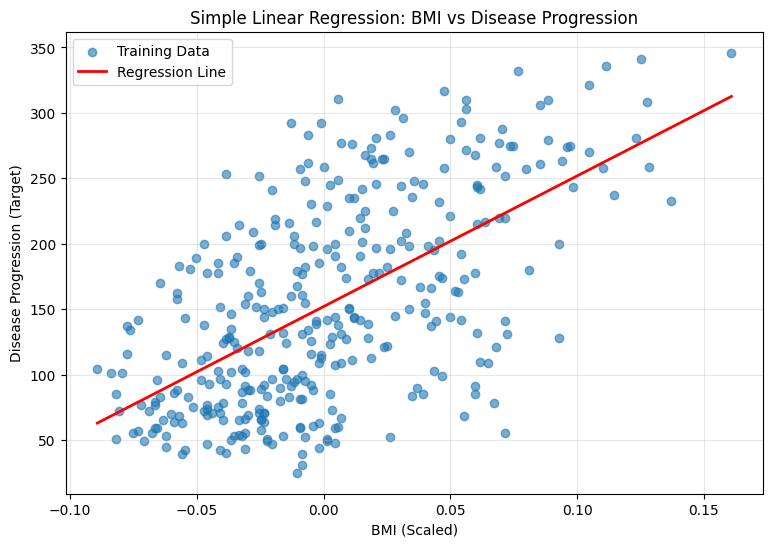

In [ ]:

# Task 2.3 — Visualize the Linear Regression Line

plt.figure(figsize=(9, 6))

# Plot training observations
plt.scatter(
    X_train["bmi"],
    y_train,
    alpha=0.6,
    label="Training Data"
)

# Sort BMI values to draw a continuous line
X_sorted = X_train.sort_values(by="bmi")

# Predict target values for the sorted BMI values
y_line = model.predict(X_sorted)

# Plot the fitted regression line
plt.plot(
    X_sorted["bmi"],
    y_line,
    color="red",
    linewidth=2,
    label="Regression Line"
)

plt.title("Simple Linear Regression: BMI vs Disease Progression")
plt.xlabel("BMI (Scaled)")
plt.ylabel("Disease Progression (Target)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

#The blue dots represent the training observations,
#and the red line represents the predictions made by our Linear Regression model


### Task 2.3 — Regression Line Interpretation

The fitted regression line shows a positive relationship between BMI and disease progression.

The line captures the overall upward trend in the training data, but many observations are scattered away from it. This suggests that BMI alone cannot fully explain the variation in disease progression.

The vertical distance between each observation and the regression line represents the residual (prediction error), calculated as:

**Residual = Actual Value − Predicted Value**

A positive residual indicates that the model underestimated the actual value, while a negative residual indicates that it overestimated the value.

In [ ]:

# Part 3 — Model Evaluation
# Task 3.1: Evaluate the simple linear regression model

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict target values using the test dataset
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display results
print("Simple Linear Regression Evaluation")
print("-----------------------------------")
print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")


Simple Linear Regression Evaluation
-----------------------------------
MAE:  52.2600
MSE:  4061.8259
RMSE: 63.7325
R²:   0.2334


### Task 3.1 — Model Evaluation

The Simple Linear Regression model was evaluated on 89 test observations.

**Evaluation results:**
- MAE: 52.2600
- MSE: 4061.8259
- RMSE: 63.7325
- R²: 0.2334

**1. How are MAE and RMSE different?**

MAE measures the average absolute prediction error, while RMSE is the square root of the average squared error. RMSE is more sensitive to large errors.

**2. Why does RMSE penalize large errors more?**

RMSE is calculated using squared errors. Squaring makes larger errors contribute disproportionately to the final metric.

**3. Interpret the R² value.**

The model achieved an R² of 0.2334, indicating that BMI alone explains approximately 23.34% of the variation in the test target values relative to a mean-based reference. This suggests limited predictive performance.

**4. Can test R² be negative?**

Yes. A negative test R² indicates that the model performs worse than predicting the mean of the test target values.

In [ ]:

# Task 3.2 — Compare Linear Regression with a Baseline

from sklearn.dummy import DummyRegressor

# Create baseline model using the training target mean
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

# Predict target values for the test observations
baseline_pred = baseline.predict(X_test)

# Evaluate baseline model
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_mse = mean_squared_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(baseline_mse)
baseline_r2 = r2_score(y_test, baseline_pred)

# Compare both models
comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R²"],
    "Linear Regression": [mae, rmse, r2],
    "Baseline": [baseline_mae, baseline_rmse, baseline_r2]
})

print("Model Comparison:")
display(comparison.round(4))


Model Comparison:


,Metric,Linear Regression,Baseline
0,MAE,52.2600,64.0065
1,RMSE,63.7325,73.2225
2,R²,0.2334,-0.0120


### Task 3.2 — Baseline Comparison

**1. Does Linear Regression outperform the baseline?**

Yes. Linear Regression achieved a lower MAE (52.2600 vs. 64.0065), a lower RMSE (63.7325 vs. 73.2225), and a higher R² (0.2334 vs. -0.0120).

**2. Why is comparing against a baseline useful?**

A baseline provides a simple reference for evaluating model performance. It helps determine whether the trained model provides meaningful predictive improvements over a basic strategy, such as always predicting the training target mean.

**3. What would worse-than-baseline performance suggest?**

If Linear Regression performed worse than the baseline, it would suggest that the model was not learning a useful predictive relationship or was failing to generalize to unseen data. This could indicate problems with model assumptions, feature selection, or data quality.

**Conclusion:** The BMI-only Linear Regression model outperforms the mean baseline, although its predictive performance remains limited.

In [ ]:

# Part 4 — Multiple Linear Regression
# Train a model using all 10 features

# Separate independent variables and target
X_all = df.drop(columns=["target"])
y_all = df["target"]

# Split data into training and testing sets
X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(
    X_all,
    y_all,
    test_size=0.2,
    random_state=42
)

# Train multiple linear regression
multiple_model = LinearRegression()
multiple_model.fit(X_train_all, y_train_all)

# Generate predictions
y_pred_all = multiple_model.predict(X_test_all)

# Calculate evaluation metrics
multiple_mae = mean_absolute_error(y_test_all, y_pred_all)
multiple_mse = mean_squared_error(y_test_all, y_pred_all)
multiple_rmse = np.sqrt(multiple_mse)
multiple_r2 = r2_score(y_test_all, y_pred_all)

# Compare simple and multiple regression
model_comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R²"],
    "Simple Regression": [mae, rmse, r2],
    "Multiple Regression": [
        multiple_mae,
        multiple_rmse,
        multiple_r2
    ]
})

print("Simple vs Multiple Linear Regression:")
display(model_comparison.round(4))

# Display regression coefficients
coefficients = pd.DataFrame({
    "Feature": X_all.columns,
    "Coefficient": multiple_model.coef_
})

print("\nMultiple Regression Coefficients:")
display(coefficients.round(4))

print(f"\nIntercept: {multiple_model.intercept_:.4f}")


Simple vs Multiple Linear Regression:


,Metric,Simple Regression,Multiple Regression
0,MAE,52.2600,42.7941
1,RMSE,63.7325,53.8534
2,R²,0.2334,0.4526



Multiple Regression Coefficients:


,Feature,Coefficient
0,age,37.9040
1,sex,-241.9644
2,bmi,542.4288
3,bp,347.7038
4,s1,-931.4888
5,s2,518.0623
6,s3,163.4200
7,s4,275.3179
8,s5,736.1989
9,s6,48.6707



Intercept: 151.3456


### Part 4 — Multiple Linear Regression Interpretation

**1. Did adding more features improve performance?**

Yes. Multiple Linear Regression outperformed Simple Linear Regression. MAE decreased from 52.2600 to 42.7941, RMSE decreased from 63.7325 to 53.8534, and R² increased from 0.2334 to 0.4526.

**2. Do more features always improve performance on unseen data?**

No. Adding more features does not guarantee better generalization. Irrelevant or noisy features may increase model complexity and contribute to overfitting.

**3. Which coefficients are positive versus negative?**

The positive coefficients are age, bmi, bp, s2, s3, s4, s5, and s6. The negative coefficients are sex and s1.

A positive coefficient indicates an increase in the predicted target as that feature increases, holding other features constant. A negative coefficient indicates the opposite.

**4. Why is comparing raw coefficient magnitudes risky?**

Raw coefficient magnitudes can be misleading when features have different scales, units, or strong correlations with one another. Although this dataset contains scaled features, multicollinearity can still make coefficient magnitudes difficult to interpret.

**Conclusion:** Multiple Linear Regression performs better on the test set, suggesting that using additional features provides useful predictive information beyond BMI alone.

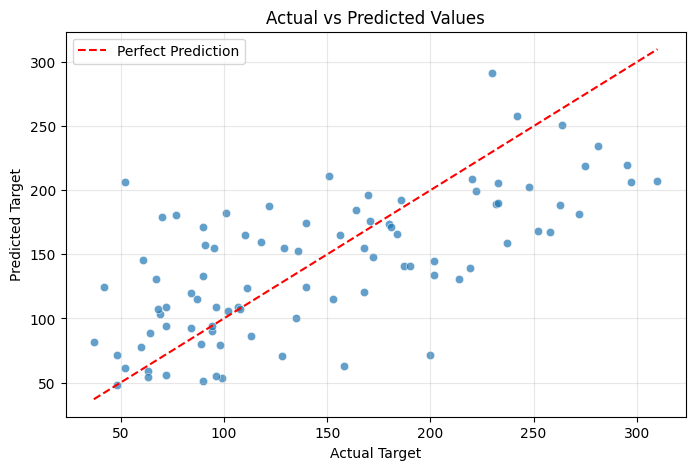

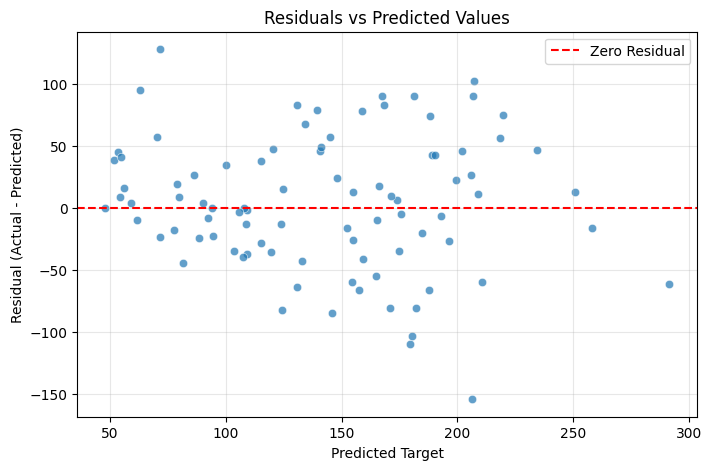

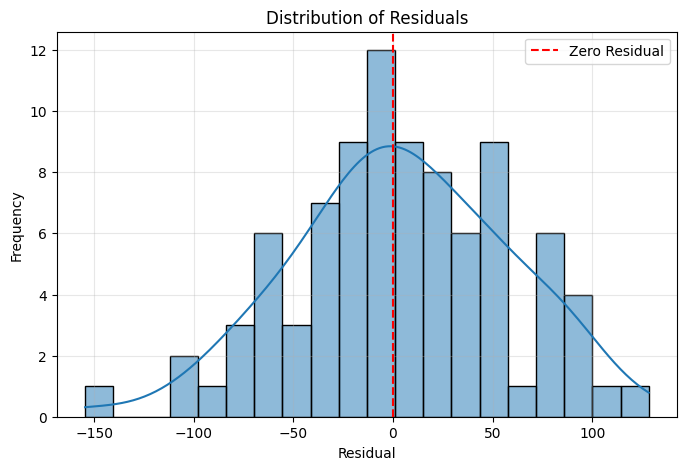

Residual Summary:
Mean residual: 3.9128
Standard deviation: 54.0154
Minimum residual: -154.4934
Maximum residual: 128.3333


In [ ]:

# Part 5 — Residual Analysis
# Analyze prediction errors for Multiple Linear Regression

# Generate predictions
y_pred_all = multiple_model.predict(X_test_all)

# Calculate residuals
residuals = y_test_all - y_pred_all

# Plot 1: Actual vs Predicted
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=y_test_all,
    y=y_pred_all,
    alpha=0.7
)

plt.plot(
    [y_test_all.min(), y_test_all.max()],
    [y_test_all.min(), y_test_all.max()],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.title("Actual vs Predicted Values")
plt.xlabel("Actual Target")
plt.ylabel("Predicted Target")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Plot 2: Residuals vs Predicted
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=y_pred_all,
    y=residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero Residual"
)

plt.title("Residuals vs Predicted Values")
plt.xlabel("Predicted Target")
plt.ylabel("Residual (Actual - Predicted)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Plot 3: Residual Histogram
plt.figure(figsize=(8, 5))

sns.histplot(
    residuals,
    bins=20,
    kde=True
)

plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    label="Zero Residual"
)

plt.title("Distribution of Residuals")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Residual statistics
print("Residual Summary:")
print(f"Mean residual: {residuals.mean():.4f}")
print(f"Standard deviation: {residuals.std():.4f}")
print(f"Minimum residual: {residuals.min():.4f}")
print(f"Maximum residual: {residuals.max():.4f}")


### Part 5 — Residual Analysis

**1. Are residuals centered around zero?**

The residuals are approximately centered around zero, with a mean of 3.9128. The histogram shows that most residuals are relatively close to zero, although the distribution is not perfectly symmetric.

**2. Is there a systematic pattern?**

The residuals-versus-predicted plot does not show a strong, obvious curved pattern. However, the spread of residuals varies across predicted values, suggesting that the model may not capture all characteristics of the data.

**3. Are there unusually large errors?**

Yes. The minimum residual is -154.4934, and the maximum residual is 128.3333. These values indicate that some individual predictions differ substantially from their actual values.

**4. What might a curved residual pattern indicate?**

A curved pattern in residuals may indicate a nonlinear relationship that the linear regression model has not adequately captured. In such cases, nonlinear features or a more flexible model may improve performance.

**Conclusion:** The residual analysis suggests that Multiple Linear Regression captures some of the relationship between the features and the target, but substantial prediction errors remain.

In [ ]:

# Part 6 — Cross-Validation
# Evaluate the stability of Multiple Linear Regression

from sklearn.model_selection import cross_val_score

# Perform 5-fold cross-validation on training data only
cv_scores = cross_val_score(
    LinearRegression(),
    X_train_all,
    y_train_all,
    cv=5,
    scoring="r2"
)

# Display individual fold scores
print("Cross-Validation R² Scores:")
for i, score in enumerate(cv_scores, start=1):
    print(f"Fold {i}: {score:.4f}")

# Calculate mean and standard deviation
print(f"\nMean R²: {cv_scores.mean():.4f}")
print(f"Standard Deviation: {cv_scores.std():.4f}")


Cross-Validation R² Scores:
Fold 1: 0.5476
Fold 2: 0.3612
Fold 3: 0.5048
Fold 4: 0.6177
Fold 5: 0.2149

Mean R²: 0.4493
Standard Deviation: 0.1441


### Part 6 — Cross-Validation Interpretation

**1. Why use cross-validation rather than only one split?**

Cross-validation evaluates the model across multiple training and validation partitions, reducing reliance on a single data split and providing a more informative estimate of generalization performance.

**2. What does a large standard deviation across folds suggest?**

A large standard deviation suggests that model performance varies across different validation subsets. This may indicate sensitivity to the data split and limited performance stability.

**3. Why should the final test set remain separate?**

The final test set should remain untouched during model development to provide an independent evaluation of generalization performance and reduce the risk of overfitting model decisions to the test data.

**4. Based on these scores, is the model reliable?**

The model demonstrates moderate predictive ability, with a mean cross-validation R² of 0.4493. However, the standard deviation of 0.1441 and the variation between folds (0.2149 to 0.6177) indicate that performance is not fully stable.

The test R² of 0.4526 is close to the cross-validation mean, which is encouraging, but the model still has limitations in predictive accuracy and consistency.

## Part 7 — Final Discussion

**9. Which model would you choose? Justify using evaluation metrics.**

I would choose Multiple Linear Regression because it achieved the best performance on the test dataset. Its MAE was 42.7941, RMSE was 53.8534, and R² was 0.4526, outperforming the BMI-only model (MAE = 52.2600, RMSE = 63.7325, R² = 0.2334). The cross-validation mean R² of 0.4493 also supports its moderate predictive performance.

**10. Suppose training R² is 0.95 but test R² is 0.30. What might explain this?**

This large performance gap suggests overfitting. The model may have learned patterns or noise specific to the training data that do not generalize well to unseen observations.

**11. Suggest at least two ways to improve the model.**

- Apply Ridge or Lasso regularization to control coefficient instability and reduce potential overfitting.
- Explore nonlinear relationships using polynomial features or more flexible regression models.
- Use cross-validation to compare model configurations and assess their consistency.

**12. Why use numerical metrics and visualizations together?**

Numerical metrics summarize overall prediction accuracy, while visualizations reveal patterns that the metrics may not capture, such as outliers, nonlinear relationships, systematic prediction errors, and unequal residual variability.

### Final Conclusion

This lab investigated the use of Linear Regression to predict diabetes disease progression using the scikit-learn Diabetes dataset, which contains 442 observations and 10 numerical features. Initial exploration showed a moderate positive relationship between BMI and disease progression, with a correlation of approximately 0.5865.

The BMI-only Linear Regression model achieved a test MAE of 52.2600, RMSE of 63.7325, and R² of 0.2334, outperforming the mean baseline model. When all 10 features were included, performance improved substantially, with MAE decreasing to 42.7941, RMSE decreasing to 53.8534, and R² increasing to 0.4526.

Residual analysis showed that prediction errors were approximately centered around zero, although some unusually large errors remained. Five-fold cross-validation produced a mean R² of 0.4493 with a standard deviation of 0.1441, indicating moderate predictive ability with some variability across folds.

Overall, Multiple Linear Regression was the better-performing approach. However, its predictive power remains limited, and future improvements could include regularization, nonlinear feature engineering, and additional model comparisons.